# Clasificación de cobertura de suelo con datos de Sentinel-2

**Geocomputación (1GEO20)** — PUCP, 2026-II — Semana 12

En este notebook se clasifica la cobertura de suelo de una zona de la Amazonía peruana a partir de seis bandas de Sentinel-2, usando como referencia el mapa de MapBiomas Perú. Se arma una tabla de píxeles, se entrenan un árbol de decisión y un Random Forest, se evalúan con una partición por zonas y se genera un mapa de toda la imagen. El flujo se controla desde la celda de parámetros y usa funciones de `utils_clasificacion.py`, que se reutilizan en la práctica.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import ListedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

import utils_clasificacion as uc

## Parámetros

In [ ]:
AOI = "puerto_maldonado"
ANIO = 2025
CARPETA = "data/datos_clasificacion/"

# Agrupación de las clases de MapBiomas (nombre de la clase: códigos originales)
AGRUPACION = {
    "Bosque": [3],
    "Bosque inundable": [6],
    "Pasto, agropecuario y herbazal": [15, 21, 51],
    "Suelo sin vegetación": [23, 25],
    "Urbano": [24],
    "Minería": [30],
    "Agua": [33],
}

MUESTRAS_POR_CLASE = 1500   # máximo de píxeles por clase en la muestra
MIN_PIXELES = 2000          # una clase con menos píxeles en la imagen se descarta
PROP_PRUEBA = 0.2           # proporción de la muestra (o de bloques) para prueba
TAM_BLOQUE = 100            # lado del bloque, en píxeles (1 píxel = 30 m)
MODELO = "rf"               # modelo para evaluar y mapear: "rf" o "arbol"
SEMILLA = 42
GUARDAR_FIGURAS = True      # guarda las figuras en la carpeta figuras/

## Datos

La imagen tiene seis bandas de Sentinel-2 en reflectancia, alineadas a la grilla de MapBiomas. Los píxeles con nubes o sombras están como NaN.

In [ ]:
with rasterio.open(CARPETA + f"s2_bandas_{ANIO}_{AOI}.tif") as src:
    pila = src.read()                      # forma (bandas, alto, ancho)
    bandas = list(src.descriptions)
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

with rasterio.open(CARPETA + f"mapbiomas_col4_{ANIO}_{AOI}.tif") as src:
    mapbiomas = src.read(1)

print("Imagen:", pila.shape, bandas)
print("MapBiomas:", mapbiomas.shape)

Imagen: (6, 743, 744) ['B02', 'B03', 'B04', 'B08', 'B11', 'B12']
MapBiomas: (743, 744)


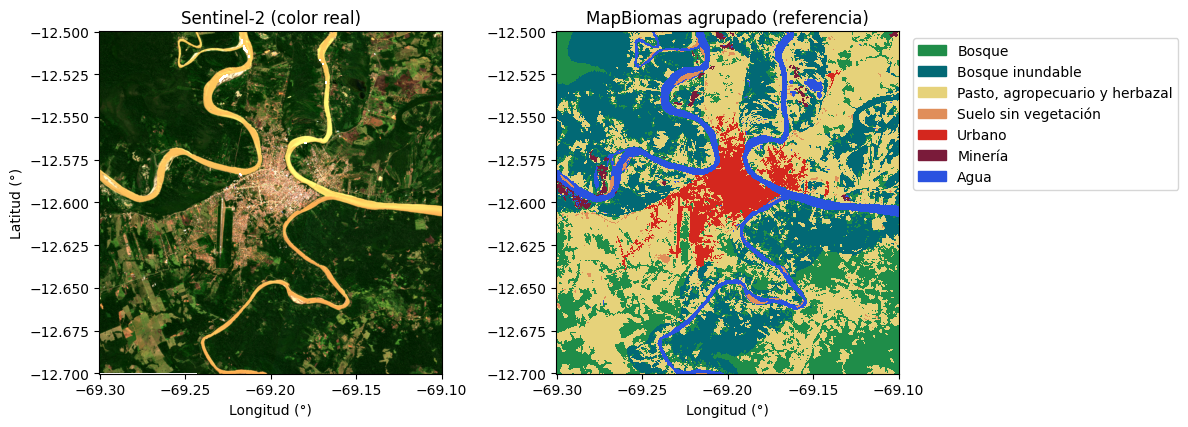

In [15]:
grupos, nombres = uc.agrupar_clases(mapbiomas, AGRUPACION)
colores = uc.colores_para(nombres)

# Composición en color real (B04, B03, B02)
rgb = np.moveaxis(pila[[bandas.index(b) for b in ("B04", "B03", "B02")]], 0, -1)
p2, p98 = np.nanpercentile(rgb, (2, 98))
rgb = np.clip((rgb - p2) / (p98 - p2), 0, 1)

fig, ejes = plt.subplots(1, 2, figsize=(12, 5.5))
ejes[0].imshow(rgb, extent=extent)
ejes[0].set_title("Sentinel-2 (color real)")
ejes[1].imshow(np.ma.masked_equal(grupos, 0), cmap=ListedColormap(colores),
               vmin=0.5, vmax=len(nombres) + 0.5, extent=extent, interpolation="nearest")
ejes[1].set_title("MapBiomas agrupado (referencia)")
uc.leyenda_clases(ejes[1], nombres, colores, loc="upper left", bbox_to_anchor=(1.02, 1))
for ax in ejes:
    ax.set_xlabel("Longitud (°)")
ejes[0].set_ylabel("Latitud (°)")
plt.tight_layout()
uc.guardar_figura(fig, "01_imagen_y_referencia", GUARDAR_FIGURAS)
plt.show()

## Del ráster a la tabla

Cada píxel pasa a ser una fila de la tabla, con una columna por banda. La clase de cada píxel sale del mapa de referencia. Se excluyen los píxeles sin datos y los que no pertenecen a ninguna clase.

In [16]:
n_bandas, alto, ancho = pila.shape

X_todo = pila.reshape(n_bandas, -1).T          # una fila por píxel, una columna por banda
y_todo = grupos.ravel()                         # clase de cada píxel (0 = sin clase)
filas, columnas = np.divmod(np.arange(alto * ancho), ancho)   # posición de cada píxel

valido = ~np.isnan(X_todo).any(axis=1) & (y_todo > 0)
X_todo, y_todo = X_todo[valido], y_todo[valido]
filas, columnas = filas[valido], columnas[valido]

print(f"Imagen: {alto} x {ancho} = {alto * ancho} píxeles")
print(f"Tabla:  {X_todo.shape[0]} filas x {X_todo.shape[1]} columnas")

ejemplo = np.random.default_rng(SEMILLA).choice(len(y_todo), size=6, replace=False)
tabla = pd.DataFrame(X_todo[ejemplo], columns=bandas).round(3)
tabla["clase"] = [nombres[k - 1] for k in y_todo[ejemplo]]
tabla

Imagen: 743 x 744 = 552792 píxeles
Tabla:  552218 filas x 6 columnas


,B02,B03,B04,B08,B11,B12,clase
0,0.026,0.050,0.033,0.338,0.218,0.107,"Pasto, agropecuario y herbazal"
1,0.023,0.044,0.026,0.289,0.150,0.062,Bosque
2,0.025,0.056,0.027,0.360,0.208,0.093,"Pasto, agropecuario y herbazal"
3,0.020,0.036,0.022,0.249,0.160,0.070,Bosque
4,0.023,0.044,0.025,0.284,0.154,0.068,Bosque inundable
5,0.018,0.035,0.021,0.245,0.121,0.052,Bosque inundable


## Muestra de entrenamiento y prueba

Se toma una muestra con el mismo máximo de píxeles por clase, para que las clases poco frecuentes tengan ejemplos suficientes. Las clases con muy pocos píxeles en la imagen se descartan.

Como cada clase aporta un número parecido de muestras, la exactitud global que se calcula más adelante no equivale al porcentaje del área bien clasificada.

In [17]:
idx, clases = uc.muestrear_por_clase(y_todo, MUESTRAS_POR_CLASE, MIN_PIXELES, SEMILLA, nombres)
X, y = X_todo[idx], y_todo[idx]
f, c = filas[idx], columnas[idx]
nombres_clases = [nombres[k - 1] for k in clases]

pd.Series([nombres[k - 1] for k in y]).value_counts().rename("píxeles en la muestra").to_frame()

,píxeles en la muestra
Bosque inundable,1500
"Pasto, agropecuario y herbazal",1500
Bosque,1500
Minería,1500
Suelo sin vegetación,1500
Agua,1500
Urbano,1500


## Partición

Se comparan dos formas de separar entrenamiento y prueba. En la partición aleatoria, un píxel de prueba suele tener vecinos casi idénticos en el entrenamiento. En la partición por bloques, zonas completas quedan reservadas para la prueba.

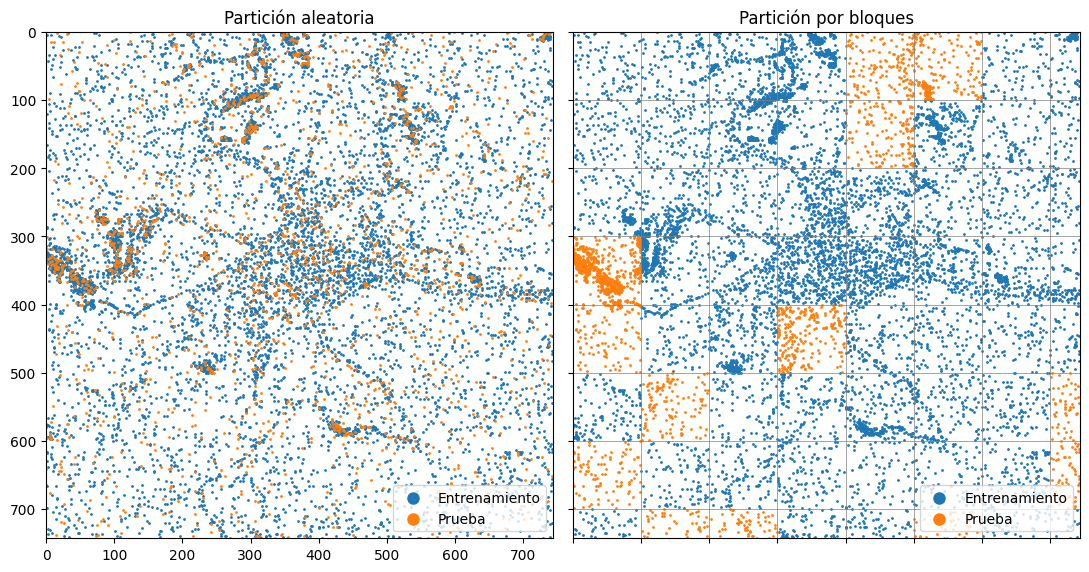

In [7]:
# Partición aleatoria
idx_ent, idx_pru = train_test_split(np.arange(len(y)), test_size=PROP_PRUEBA, random_state=SEMILLA)
es_prueba_azar = np.zeros(len(y), dtype=bool)
es_prueba_azar[idx_pru] = True

# Partición por bloques
es_prueba_bloques = uc.dividir_por_bloques(f, c, TAM_BLOQUE, PROP_PRUEBA, SEMILLA, y=y)

fig, ejes = plt.subplots(1, 2, figsize=(11, 5.5))
uc.mapa_particion(f, c, es_prueba_azar, (alto, ancho), ejes[0], "Partición aleatoria")
uc.mapa_particion(f, c, es_prueba_bloques, (alto, ancho), ejes[1], "Partición por bloques", tam_bloque=TAM_BLOQUE)
plt.tight_layout()
uc.guardar_figura(fig, "02_particion", GUARDAR_FIGURAS)
plt.show()

## Entrenamiento

Se entrenan un árbol de decisión sin límite de profundidad y un Random Forest, con la partición por bloques. La comparación entre la exactitud en entrenamiento y en prueba muestra cuánto sobreajusta cada uno.

In [18]:
X_ent, X_pru = X[~es_prueba_bloques], X[es_prueba_bloques]
y_ent, y_pru = y[~es_prueba_bloques], y[es_prueba_bloques]
print(f"Entrenamiento: {len(y_ent)} píxeles   Prueba: {len(y_pru)} píxeles")

arbol = DecisionTreeClassifier(random_state=SEMILLA).fit(X_ent, y_ent)     # sin límite de profundidad
bosque = RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1).fit(X_ent, y_ent)

for nombre, m in [("Árbol de decisión", arbol), ("Random Forest", bosque)]:
    print(f"{nombre:18s} entrenamiento {m.score(X_ent, y_ent):.3f}   prueba {m.score(X_pru, y_pru):.3f}")
print("Profundidad del árbol:", arbol.get_depth())

Entrenamiento: 8480 píxeles   Prueba: 2020 píxeles
Árbol de decisión  entrenamiento 1.000   prueba 0.595
Random Forest      entrenamiento 1.000   prueba 0.665
Profundidad del árbol: 24


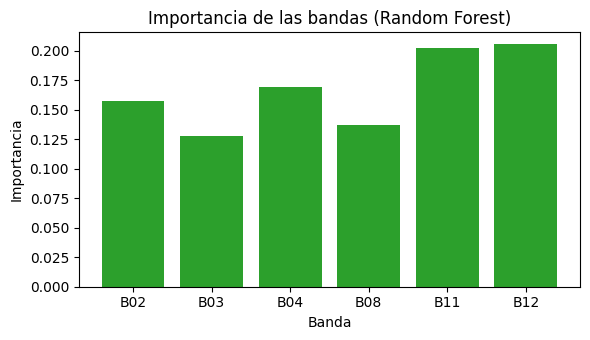

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(bandas, bosque.feature_importances_, color="tab:green")
ax.set_xlabel("Banda")
ax.set_ylabel("Importancia")
ax.set_title("Importancia de las bandas (Random Forest)")
plt.tight_layout()
uc.guardar_figura(fig, "03_importancia_bandas", GUARDAR_FIGURAS)
plt.show()

## Evaluación

La matriz de confusión compara la clase de referencia (filas) con la clase predicha (columnas), usando solo los datos de prueba. El modelo evaluado depende del parámetro `MODELO`.

Exactitud global en prueba: 0.595

                                Exactitud del usuario  \
Bosque                                          0.687   
Bosque inundable                                0.456   
Pasto, agropecuario y herbazal                  0.669   
Suelo sin vegetación                            0.344   
Urbano                                          0.532   
Minería                                         0.742   
Agua                                            0.667   

                                Exactitud del productor  Píxeles de prueba  
Bosque                                            0.504                353  
Bosque inundable                                  0.688                186  
Pasto, agropecuario y herbazal                    0.617                337  
Suelo sin vegetación                              0.515                200  
Urbano                                            0.598                169  
Minería                                       

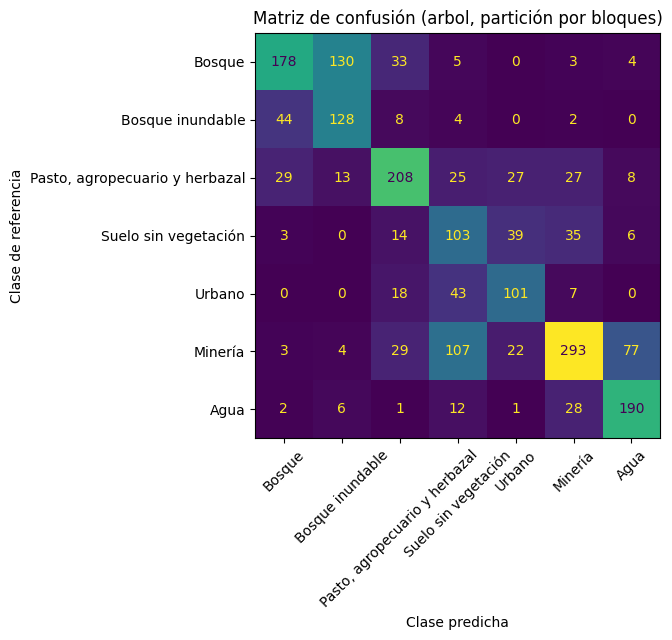

In [19]:
modelo = {"arbol": arbol, "rf": bosque}[MODELO]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
uc.evaluar(modelo, X_pru, y_pru, clases, nombres_clases, ax=ax,
           titulo=f"Matriz de confusión ({MODELO}, partición por bloques)")
plt.tight_layout()
uc.guardar_figura(fig, "04_matriz_confusion_{MODELO}", GUARDAR_FIGURAS)
plt.show()

In [20]:
# Mismo modelo, entrenado con la partición aleatoria
bosque_azar = RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1)
bosque_azar.fit(X[~es_prueba_azar], y[~es_prueba_azar])

print(f"Random Forest, exactitud en prueba con partición aleatoria:   {bosque_azar.score(X[es_prueba_azar], y[es_prueba_azar]):.3f}")
print(f"Random Forest, exactitud en prueba con partición por bloques: {bosque.score(X_pru, y_pru):.3f}")

Random Forest, exactitud en prueba con partición aleatoria:   0.707
Random Forest, exactitud en prueba con partición por bloques: 0.665


## Predicción sobre toda la imagen

El modelo clasifica todos los píxeles con datos y el resultado se reordena con la forma de la imagen. Los píxeles sin datos quedan en blanco.

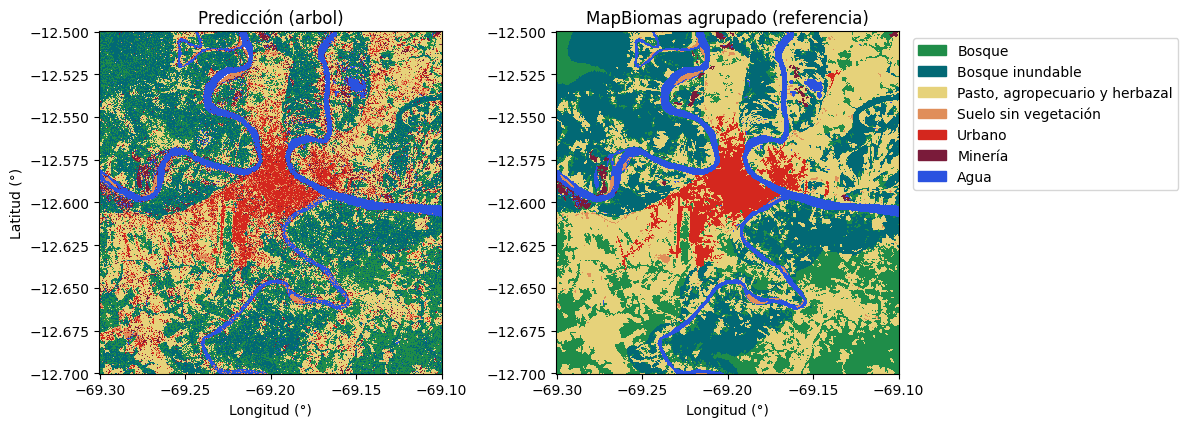

In [21]:
mapa_pred = uc.predecir_imagen(modelo, pila)

# Referencia con las mismas clases que el modelo (sin las clases descartadas)
referencia = np.where(np.isin(grupos, clases), grupos, 0)

fig, ejes = plt.subplots(1, 2, figsize=(12, 5.5))
opciones = dict(cmap=ListedColormap(colores), vmin=0.5, vmax=len(nombres) + 0.5, extent=extent, interpolation="nearest")
ejes[0].imshow(np.ma.masked_invalid(np.where(mapa_pred > 0, mapa_pred, np.nan)), **opciones)
ejes[0].set_title(f"Predicción ({MODELO})")
ejes[1].imshow(np.ma.masked_equal(referencia, 0), **opciones)
ejes[1].set_title("MapBiomas agrupado (referencia)")
uc.leyenda_clases(ejes[1], nombres_clases, [colores[k - 1] for k in clases], loc="upper left", bbox_to_anchor=(1.02, 1))
for ax in ejes:
    ax.set_xlabel("Longitud (°)")
ejes[0].set_ylabel("Latitud (°)")
plt.tight_layout()
uc.guardar_figura(fig, "05_prediccion_{MODELO}_vs_referencia", GUARDAR_FIGURAS)
plt.show()